In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
from dask.diagnostics import ProgressBar
import rasterio.features as features
import glob
from netCDF4 import Dataset
from shapely.geometry import box

## Open data

In [2]:
path_refl_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CAC/AVN14/2002/CACin2002*.nc'

In [3]:
path_angle_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CAA/AVN14/2002/CAAin2002*.nc'

In [4]:
path_cloud_data = '/mnt/data3/nfs4/cci_snow_3/composites/beta/CMA/AVN14/2002/CMAin2002*.nc'

In [5]:
path_SCFV_data = '/scratch/mpekkala/SCFV_2002/*.nc'

In [6]:
path_map = '/scratch/mpekkala/Transmissivity_maps/World_Continents/World_Continents.shp'

In [7]:
path_Kemijoki = '/scratch/mpekkala/Transmissivity_maps/Kemijoki_4326/Kemijoki_grid_5000.shp'

In [8]:
path_Kemijoki_MODIS = '/scratch/mpekkala/Transmissivity_maps/MODIS_transmissivity/Baltic_trans2_005deg_2011_2Kemijokigrid_1km.tif'

In [9]:
path_ENVEO_transmissivity = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/20200710_CANOPY_CORRECTION_LAYER_TCD_LCCCI_2000_v01_005deg.tif'

In [10]:
path_ENVEO_icemask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/icemask50.tif'

In [11]:
path_ENVEO_watermask = '/scratch/mpekkala/Transmissivity_maps/ENVEO_transmissivity/watermask50.tif'

In [12]:
path_topo = '/scratch/mpekkala/NOAA_topography/ETOPO_2022_v1_60s_N90W180_bed.nc'

In [13]:
ds_refl = xr.open_mfdataset(path_refl_data)

/tmp/ipykernel_190304/4140158708.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_refl = xr.open_mfdataset(path_refl_data)


In [14]:
ds_angle = xr.open_mfdataset(path_angle_data)

/tmp/ipykernel_190304/3170950570.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_angle = xr.open_mfdataset(path_angle_data)


In [15]:
ds_cloud = xr.open_mfdataset(path_cloud_data)

/tmp/ipykernel_190304/22790263.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_cloud = xr.open_mfdataset(path_cloud_data)


In [16]:
ds_SCFV = xr.open_mfdataset(path_SCFV_data)

/tmp/ipykernel_190304/2424410955.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_SCFV = xr.open_mfdataset(path_SCFV_data)


In [17]:
Map = gpd.read_file(path_map)

In [80]:
#topography = xr.open_mfdataset(path_topo)

In [19]:
#MODIS = rioxarray.open_rasterio(path_Kemijoki_MODIS)

In [20]:
#ENVEO = rioxarray.open_rasterio(path_ENVEO_transmissivity)

In [21]:
#ENVEO_ice = rioxarray.open_rasterio(path_ENVEO_icemask)

In [22]:
#ENVEO_water = rioxarray.open_rasterio(path_ENVEO_watermask)

In [23]:
#Kemijoki = gpd.read_file(path_Kemijoki)

## Calculate reflectance

In [18]:
reflectance_asc = ds_refl["refl_vis006_asc"]/np.cos(np.deg2rad(ds_angle["sunzen_asc"]))

In [19]:
reflectance_desc = ds_refl["refl_vis006_desc"]/np.cos(np.deg2rad(ds_angle["sunzen_desc"]))

In [20]:
da_refl_asc = reflectance_asc

da_refl_asc = da_refl_asc.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl_asc = da_refl_asc.rio.write_crs("EPSG:4326")

In [21]:
da_refl_desc = reflectance_desc

da_refl_desc = da_refl_desc.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da_refl_desc = da_refl_desc.rio.write_crs("EPSG:4326")

# Save memory

In [22]:
da_refl_asc = da_refl_asc.astype("float32")
da_refl_desc = da_refl_desc.astype("float32")

# Mask clouds

In [23]:
da_cloud_asc = ds_cloud["cma_prob_asc"]

In [24]:
da_cloud_desc = ds_cloud["cma_prob_desc"]

In [25]:
cloud_mask_asc = da_cloud_asc <= 0.8

In [26]:
cloud_mask_desc = da_cloud_desc <= 0.8

In [27]:
da_refl_asc = da_refl_asc.where(cloud_mask_asc)

In [28]:
da_refl_desc = da_refl_desc.where(cloud_mask_desc)

# Mask clouds 2

In [31]:
#da_cloud_asc = ds_cloud["cma_asc"]

In [32]:
#da_cloud_desc = ds_cloud["cma_desc"]

In [33]:
#cloud_mask_asc = da_cloud_asc == 0

In [34]:
#cloud_mask_desc = da_cloud_desc == 0

In [35]:
#da_refl_asc = da_refl_asc.where(cloud_mask_asc)

In [36]:
#da_refl_desc = da_refl_desc.where(cloud_mask_desc)

# Mask angles

In [29]:
sunzen_mask_asc = (ds_angle["sunzen_asc"] <= 85)

In [30]:
sunzen_mask_desc = (ds_angle["sunzen_desc"] <= 85)

In [31]:
da_refl_asc = da_refl_asc.where(sunzen_mask_asc)

In [32]:
da_refl_desc = da_refl_asc.where(sunzen_mask_desc)

In [33]:
satzen_mask_asc = (ds_angle["satzen_asc"] <= 45)

In [34]:
satzen_mask_desc = (ds_angle["satzen_desc"] <= 45)

In [35]:
da_refl_asc = da_refl_asc.where(satzen_mask_asc)

In [36]:
da_refl_desc = da_refl_desc.where(satzen_mask_desc)

# Mask SCFV

In [37]:
da_SCFV = (ds_SCFV["scfv"] >= 80) & (ds_SCFV["scfv"] <= 100)

In [38]:
da_refl_asc = da_refl_asc.where(da_SCFV)

In [39]:
da_refl_desc = da_refl_desc.where(da_SCFV)

# Combine asc and desc reflectance

In [40]:
def clean(da):
    return da.where((da > 0) & (da <= 1.0))   # zeros, negatives and junk become NaN

da_refl_mean = xr.concat(
    [clean(da_refl_asc), clean(da_refl_desc)], dim="time"
).mean(dim="time", skipna=True)

# Calculate transmissivity

In [41]:
t2 = (da_refl_mean - 0.08) / (0.65 - 0.08)

In [42]:
t2

<xarray.DataArray (lat: 3600, lon: 7200)> Size: 104MB
dask.array<truediv, shape=(3600, 7200), dtype=float32, chunksize=(1200, 2400), chunktype=numpy.ndarray>
Coordinates:
  * lat          (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon          (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    valid_min:      0
    standard_name:  solar_zenith_angle

# Free up memory

In [42]:
import gc

In [43]:
del reflectance_asc, reflectance_desc, da_refl_asc, da_refl_desc, da_cloud_asc, cloud_mask_asc, da_cloud_desc, cloud_mask_desc, sunzen_mask_asc, sunzen_mask_desc, satzen_mask_asc, satzen_mask_desc, da_SCFV, da_refl_mean

In [44]:
# Force garbage collection
gc.collect()

60

# Save data

In [45]:
t2.attrs["standard_name"] = "t2"

In [46]:
with ProgressBar():
    t2.to_netcdf("/scratch/mpekkala/Transmissivity_maps/1998_2002_transmissivity_data/t2_2002.nc")

[########################################] | 100% Completed | 16m 43s


# Plot global transmissivity

# Masked (cloud 0.8, angles, SCFV)

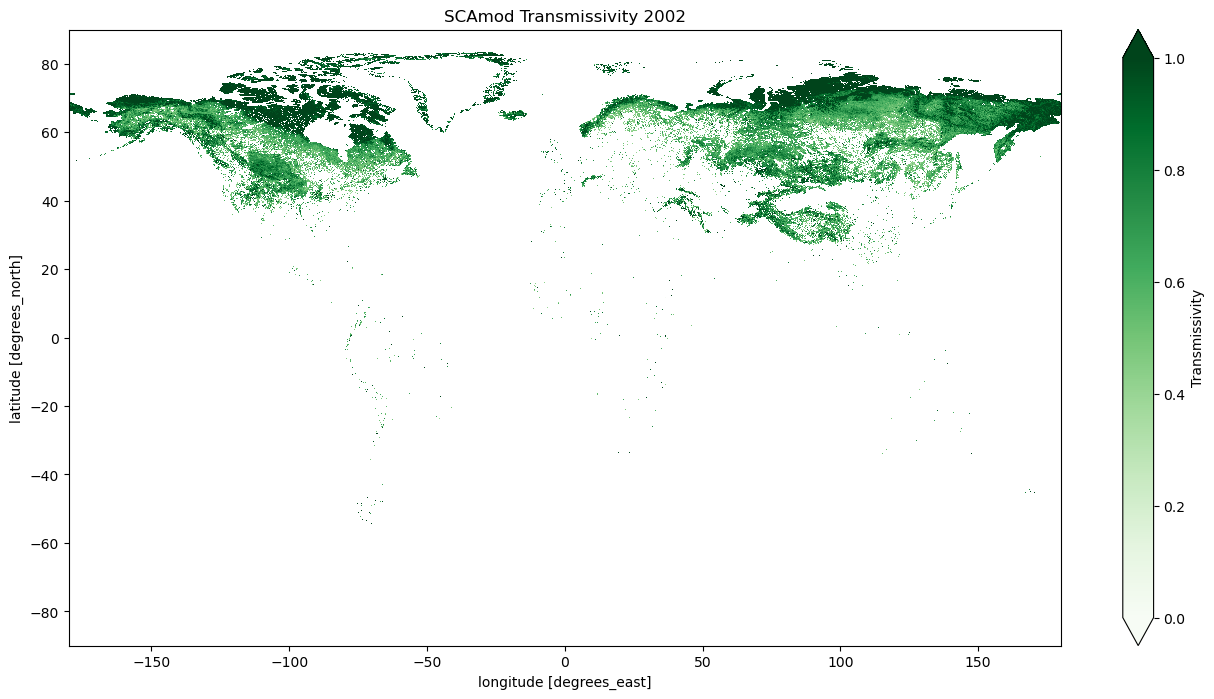

In [47]:
import os
import xarray as xr
import matplotlib.pyplot as pyplot

t2 = xr.open_dataarray("/scratch/mpekkala/Transmissivity_maps/1998_2002_transmissivity_data/t2_2002.nc")      # plain NumPy-backed, plots instantly

fig, ax = pyplot.subplots(figsize=(16, 8))

t2.plot(
    ax=ax,
    cmap="Greens",
    vmin=0,
    vmax=1,
    cbar_kwargs={"label": "Transmissivity"}
)

pyplot.title("SCAmod Transmissivity 2002")

os.makedirs("Figures", exist_ok=True)
pyplot.savefig(
    "Figures/SCAmod_transmissivity_masked_2002.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
pyplot.show()